# Library

In [ ]:
# 1. Instalasi dependensi sistem untuk Tweet Harvest / Chromium
!sudo apt-get install -y ca-certificates curl gnupg
!sudo mkdir -p /etc/apt/keyrings
!curl -fsSL https://deb.nodesource.com/gpgkey/nodesource.gpg.key | sudo gpg --dearmor -o /etc/apt/keyrings/nodesource.gpg
!curl -fsSL https://deb.nodesource.com/setup_20.x | sudo -E bash -
!sudo apt-get install -y nodejs

# Memperbarui daftar paket dan menginstal pustaka GUI/Chromium pendukung
!sudo apt-get update
!sudo apt-get install -y \
    libxcomposite1 \
    libxdamage1 \
    libxfixes3 \
    libxrandr2 \
    libx11-xcb1 \
    libxcb1 \
    libxcb-dri3-0 \
    libxcb-shm0 \
    libgbm1 \
    libgtk-3-0 \
    libnss3 \
    libatk1.0-0t64 \
    libatk-bridge2.0-0t64 \
    libcups2 \
    libdrm2 \
    libasound2t64 \
    libpango-1.0-0 \
    libcairo2

# 2. Instalasi library Python pendukung
!pip install -q pandas numpy scikit-learn wordcloud transformers torch openpyxl

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ca-certificates is already the newest version (20260601~24.04.1).
curl is already the newest version (8.5.0-2ubuntu10.16).
gnupg is already the newest version (2.4.4-2ubuntu17.6).
gnupg set to manually installed.
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
2026-10-21 12:34:46 - Installing pre-requisites
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Get:8 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:9 htt

In [ ]:
# --- Standar & Utilitas Sistem ---
import os
import sys
from datetime import datetime, timezone
from collections import Counter
from google.colab import files
from IPython.display import display, Markdown

# --- Pengolahan Data & Angka ---
import pandas as pd
import numpy as np
import re

# --- Natural Language Processing (NLTK & Stopwords) ---
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

# --- Machine Learning & Scikit-Learn ---
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, r2_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics.pairwise import cosine_similarity

# --- Deep Learning & Transformers ---
import torch
from transformers import pipeline

# --- Visualisasi Data (Matplotlib, Seaborn, WordCloud) ---
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Konfigurasi awal visualisasi agar rapi
plt.style.use('ggplot')

# Crawling Data

In [ ]:
# Twitter Auth Token
twitter_auth_token = "ISI_TOKEN_DI_SINI"

In [ ]:
# Crawling 1
data = "kerja.csv"
# Kata kunci pencarian
search_keyword = 'gaji UMR OR lowongan kerja OR fresh graduate since:2026-01-01 until:2026-10-10'
# Jumlah tweet
limit = 1000

# Jalankan crawling
!npx --yes tweet-harvest -o "{data}" -s "{search_keyword}" -l {limit} --token "{twitter_auth_token}"

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼npm warn deprecated rimraf@3.0.2: Rimraf versions prior to v4 are no longer supported
⠼npm warn deprecated inflight@1.0.6: This module is not supported, and leaks memory. Do not use it. Check out lru-cache if you want a good and tested way to coalesce async requests by a key value, which is much more comprehensive and powerful.
⠴npm warn deprecated @playwright/test@1.41.1: Please update to the latest version of Playwright to test up-to-date browsers.
⠴npm warn deprecated glob@7.2.3: Old versions of glob are not supported, and contain widely publicized security vulnerabilities, which have been fixed in the current version. Please update. Support for old versions may be purchased (at exorbitant rates) by contacting i@izs.me
⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏

In [ ]:
# Crawling 2
data = "kerja2.csv"
# Kata kunci pencarian
search_keyword = 'gaji UMR OR lowongan kerja OR fresh graduate since:2026-01-01 until:2026-10-10'
# Jumlah tweet
limit = 500

# Jalankan crawling
!npx --yes tweet-harvest -o "{data}" -s "{search_keyword}" -l {limit} --token "{twitter_auth_token}"

⠙⠹⠸⠼⠴⠦⠧Tweet Harvest [v2.7.1]

Research by Helmi Satria
Use it for Educational Purposes only!

This script uses Chromium Browser to crawl data from Twitter with your Twitter auth token.
Please enter your Twitter auth token when prompted.

Note: Keep your access token secret! Don't share it with anyone else.
Note: This script only runs on your local device.


Opening twitter search page...


-- Scrolling... (1) (2)
Filling in keywords: gaji UMR OR lowongan kerja OR fresh graduate since:2026-01-01 until:2026-10-10

 (3) (4) (5)

Your tweets saved to: /content/tweets-data/kerja2.csv
Total tweets saved: 16

-- Scrolling... (1) (2)

Your tweets saved to: /content/tweets-data/kerja2.csv
Total tweets saved: 30

-- Scrolling... (1) (2) (3)

Your tweets saved to: /content/tweets-data/kerja2.csv
Total tweets saved: 46

-- Scrolling... (1)

Your tweets saved to: /content/tweets-data/kerja2.csv
Total tweets saved: 61

-- Scrolling... (1)

Your tweets saved to: /content/tweets-data/kerja2.csv
Total

# Merging

In [ ]:
# Tentukan folder tempat file CSV berada (folder utama Colab)
folder_path = '/content/tweets-data/'
all_data = []
target_files = ['kerja.csv', 'kerja2.csv']

# List file CSV yang ada di panel kiri
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv') and f != 'sample_data']

print(f"Ditemukan {len(csv_files)} file CSV: {csv_files}\n")

# Process & Gabungkan semua file CSV
for filename in csv_files:
    file_path = os.path.join(folder_path, filename)
    try:
        df = pd.read_csv(file_path)

        # Ambil nama kata kunci/sumber dari nama file
        keyword_name = os.path.splitext(filename)[0]
        df['Nama_Keyword'] = keyword_name

        all_data.append(df)
        print(f"File '{filename}' ({len(df)} baris) berhasil dimuat.")
    except Exception as e:
        print(f"Gagal memproses file '{filename}': {e}")

# Gabungkan DataFrame (Blending/Concat)
if all_data:
    df_final = pd.concat(all_data, ignore_index=True)

    # Hapus duplikat ID atau Teks jika ada tweet yang terambil 2 kali
    if 'id_str' in df_final.columns:
        df_final.drop_duplicates(subset=['id_str'], keep='first', inplace=True)
    elif 'full_text' in df_final.columns:
        df_final.drop_duplicates(subset=['full_text'], keep='first', inplace=True)

    print(f"\Blending selesai! Total data gabungan bersih: {len(df_final)} baris.")
else:
    print("\nTidak ada file CSV yang ditemukan.")

Ditemukan 2 file CSV: ['kerja.csv', 'kerja2.csv']

File 'kerja.csv' (512 baris) berhasil dimuat.
File 'kerja2.csv' (394 baris) berhasil dimuat.
\Blending selesai! Total data gabungan bersih: 650 baris.


<>:39: SyntaxWarning: invalid escape sequence '\B'
<>:39: SyntaxWarning: invalid escape sequence '\B'
/tmp/ipykernel_1287/41500594.py:39: SyntaxWarning: invalid escape sequence '\B'
  print(f"\Blending selesai! Total data gabungan bersih: {len(df_final)} baris.")


In [ ]:
from google.colab import files

# Tampilkan 5 baris pertama data gabungan
print("5 Baris Pertama Hasil Gabungan:")
display(df_final.head())

# Tentukan nama file hasil merge yang baru
nama_file_saya = 'merge_kerja.csv'

# Simpan ke folder lokal Colab
df_final.to_csv(nama_file_saya, index=False, encoding='utf-8')
print(f"\nFile berhasil disimpan dengan nama: {nama_file_saya}")

5 Baris Pertama Hasil Gabungan:


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username,Nama_Keyword
0,2108706072458572141,2026-10-09T23:48:00.000Z,37898,GOOD NEWS:\n\npemerintah akan menaikkan upah m...,2108706072458572141,NaN,NaN,in,NaN,2761,1465,4717,https://x.com/txtdrimedia/status/2108706072458...,1300484934449000448,txtdrimedia,kerja
1,2099802179079205201,2026-09-15T10:07:06.000Z,14440,"gue abis nontonin vt ini, ada yang nanya cara ...",2099802179079205201,https://pbs.twimg.com/media/HSP-800aQAA_eEE.jpg,NaN,in,NaN,315,72,1515,https://x.com/gemistale/status/209980217907920...,2052947918693552128,gemistale,kerja
2,2107764965411275126,2026-10-07T09:28:22.000Z,157,Baca di sini: https://t.co/tDQu9nSS2p\n\nLulus...,2107764965411275126,https://pbs.twimg.com/amplify_video_thumb/2107...,NaN,in,NaN,4,14,46,https://x.com/kompascom/status/210776496541127...,23343960,kompascom,kerja
3,2108025334876832235,2026-10-08T02:42:59.000Z,2550,Mimpi Basah Para Pejuang loker di Indonesia\n\...,2108025334876832235,NaN,NaN,in,NaN,39,168,818,https://x.com/supelpowel/status/21080253348768...,98409293,supelpowel,kerja
4,2094809564923465880,2026-09-01T15:28:14.000Z,590,📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi ...,2094809564923465880,https://pbs.twimg.com/media/HRJCL8ha4AA1YKv.jpg,NaN,in,NaN,2,2,46,https://x.com/Lokernas_com/status/209480956492...,1425486452243124231,Lokernas_com,kerja



File berhasil disimpan dengan nama: merge_kerja.csv


# Cleaning data

In [ ]:
# 1. Tentukan Nama File CSV di Folder Lokal Colab
file_name = 'merge_kerja.csv'  # Sesuaikan dengan nama file CSV
file_path = f'/content/{file_name}'

# 2. Muat Data ke DataFrame df
try:
    df = pd.read_csv(file_path)
    print(f"\nData berhasil dimuat: {len(df)} baris. Kolom awal: {df.columns.tolist()}")
except FileNotFoundError:
    print(f"\nERROR: File tidak ditemukan di jalur: {file_path}. Pastikan file sudah di-upload ke panel sebelah kiri.")
    raise

# 3. KOREKSI PENTING: Unduh Stopwords secara langsung
nltk.download('stopwords')
list_stopwords = set(stopwords.words('indonesian'))
print("Stopwords Indonesia siap.")


Data berhasil dimuat: 650 baris. Kolom awal: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'Nama_Keyword']
Stopwords Indonesia siap.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# --- Fungsi Pembersihan Data ---
def comprehensive_cleansing(text):
    # Case Folding
    text = str(text).lower()

    # 1. Remove URLs dan HTML Entities
    text = re.sub(r'https?://\S+|www\.\S+|x\.com/\S+', ' ', text)
    text = re.sub(r'&amp;', ' ', text)

    # 2. Remove Symbols, Mentions, Hashtags, dan Angka
    text = re.sub(r'@\w+', ' ', text)       # Hapus mentions
    text = re.sub(r'#\w+', ' ', text)       # Hapus hashtags
    text = re.sub(r'[^\w\s]', ' ', text)    # Hapus simbol/tanda baca
    text = re.sub(r'\d+', ' ', text)        # Hapus angka

    # 3. Stopwords Removal
    tokens = text.split()
    tokens_filtered = [word for word in tokens if word not in list_stopwords]
    text = ' '.join(tokens_filtered)

    # 4. Menghapus Spasi Berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# --- APLIKASI CLEANSING ---
df['Cleaned_Text'] = df['full_text'].apply(comprehensive_cleansing)
print("\n--- Pembersihan Teks (full_text -> Cleaned_Text) Selesai ---")


# --- NORMALISASI KOLOM METRIK ---
# Normalisasi created_at
if 'created_at' in df.columns:
    df['created_at_normalized'] = pd.to_datetime(
        df['created_at'],
        errors='coerce',
        utc=True
    )
    # Hapus kolom created_at lama
    df = df.drop(['created_at'], axis=1, errors='ignore')

# Normalisasi Engagement Metrics (mengisi NaN dengan 0 dan tipe data ke integer)
metrics_cols = ['favorite_count', 'quote_count', 'reply_count', 'retweet_count']
for col in metrics_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0).astype(int)

print("Normalisasi Timestamp dan Engagement Metrics Selesai.")


--- Pembersihan Teks (full_text -> Cleaned_Text) Selesai ---
Normalisasi Timestamp dan Engagement Metrics Selesai.


In [ ]:
# --- FILTERING DATA & RELEVANSI TOPIK ---

# 1. Remove Duplicate Tweets (berdasarkan Cleaned_Text)
initial_rows = len(df)
df.drop_duplicates(subset=['Cleaned_Text'], keep='first', inplace=True)
rows_after_dedup = len(df)
print(f"Total duplikasi yang dihapus: {initial_rows - rows_after_dedup} baris.")

# 2. Filtering Bahasa (hanya ambil data Bahasa Indonesia, 'in' atau 'id')
initial_rows_lang = len(df)
if 'lang' in df.columns:
    df = df[df['lang'].isin(['in', 'id'])].copy()
    rows_after_filter = len(df)
    print(f"Total baris non-Indonesia yang dihapus: {initial_rows_lang - rows_after_filter} baris.")
else:
    print("⚠️ Peringatan: Kolom 'lang' tidak ditemukan, filtering bahasa dilewati.")

# 3. [TAMBAHAN] Filter Relevansi Topik Dunia Kerja & Gen Z
keyword_dunia_kerja = [
    'gaji', 'umr', 'umk', 'upah', 'fresh graduate', 'lowongan', 'loker',
    'cari kerja', 'mencari kerja', 'kerja', 'karyawan', 'pegawai', 'boss',
    'atasan', 'kantor', 'resign', 'layoff', 'phk', 'overwork', 'burnout',
    'work life balance', 'freelance', 'magang', 'internship', 'cv', 'interview',
    'pengangguran', 'biaya hidup', 'hrd', 'rekrutmen'
]

def cek_relevansi(text):
    text_str = str(text).lower()
    return any(keyword in text_str for keyword in keyword_dunia_kerja)

initial_rows_rel = len(df)
df['is_relevant'] = df['Cleaned_Text'].apply(cek_relevansi)

# Ambil hanya data yang relevan dengan topik
df = df[df['is_relevant'] == True].reset_index(drop=True)
rows_after_rel = len(df)

print(f"=== LAPORAN FILTER RELEVANSI TOPIK ===")
print(f"Baris tidak relevan yang dibuang: {initial_rows_rel - rows_after_rel} baris")
print(f"Total baris akhir yang relevan dengan Dunia Kerja: {rows_after_rel} baris")

Total duplikasi yang dihapus: 12 baris.
Total baris non-Indonesia yang dihapus: 108 baris.
=== LAPORAN FILTER RELEVANSI TOPIK ===
Baris tidak relevan yang dibuang: 14 baris
Total baris akhir yang relevan dengan Dunia Kerja: 516 baris


In [ ]:
if 'created_at_normalized' in df.columns:
    df = df.rename(columns={'created_at_normalized': 'created_at'})
if 'full_text' in df.columns:
    df = df.rename(columns={'full_text': 'text'})
if 'favorite_count' in df.columns:
    df = df.rename(columns={'favorite_count': 'like_count'})

# Tentukan kolom yang ingin ditampilkan
kolom_tabel = [
    'created_at',
    'text',
    'Cleaned_Text',
    'like_count',
    'retweet_count',
    'reply_count',
    'is_relevant'
]

# Filter kolom yang benar-benar ada di DataFrame
kolom_display = [col for col in kolom_tabel if col in df.columns]

# Ambil 20 baris pertama
data_display = df[kolom_display].head(20)

# Ubah ke format Markdown (tabel) dan tampilkan
markdown_table = data_display.to_markdown(index=False)

print("--- 20 Baris Pertama Hasil Cleansing & Filter Relevansi ---")
display(Markdown(markdown_table))

--- 20 Baris Pertama Hasil Cleansing & Filter Relevansi ---


| created_at                | text                                                                                                                                                                                                                                                                  | Cleaned_Text                                                                                                                                                                                              |   like_count |   retweet_count |   reply_count | is_relevant   |
|:--------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-------------:|----------------:|--------------:|:--------------|
| 2026-10-09 23:48:00+00:00 | GOOD NEWS:                                                                                                                                                                                                                                                            | good news pemerintah menaikkan upah minimum rp juta fresh graduate upah minimum rp juta kenaika bertujuan meringankan beban masyarakat ditengah naiknya biaya hidup datuk anwar pm malaysia               |        37898 |            4717 |          1465 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | pemerintah akan menaikkan upah minimum menjadi Rp 8,76 juta sedangkan untuk fresh graduate upah awal minimum sebesar Rp 10,95 juta                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | kenaika ini bertujuan meringankan beban masyarakat ditengah naiknya biaya hidup. begitu kata Datuk Anwar, PM Malaysia                                                                                                                                                 |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-09-15 10:07:06+00:00 | gue abis nontonin vt ini, ada yang nanya cara kerja di ‘multinational company’ kayak dia…                                                                                                                                                                             | gue abis nontonin vt nanya kerja multinational company kayak fakta menyedihkan kasih tau job market beda fresh graduate aja susah cari kerja                                                              |        14440 |            1515 |            72 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | dan ada beberapa fakta MENYEDIHKAN yang dia kasih tau:                                                                                                                                                                                                                |                                                                                                                                                                                                           |              |                 |               |               |
|                           | - job market sekarang JAUH beda sama 2016                                                                                                                                                                                                                             |                                                                                                                                                                                                           |              |                 |               |               |
|                           | - sekarang bahkan fresh graduate aja susah cari kerja 😭😭😭😭                                                                                                                                                                                                        |                                                                                                                                                                                                           |              |                 |               |               |
|                           | - di tahun dia dulu, bahkan https://t.co/zhelStSBE6                                                                                                                                                                                                                   |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-07 09:28:22+00:00 | Baca di sini: https://t.co/tDQu9nSS2p                                                                                                                                                                                                                                 | baca lulusan smk jakarta athalla dzaky atmaja menghadapi sulitnya mencari pekerjaan lowongan mensyaratkan pengalaman berkali kali mengirim lamaran job fair situs pencari kerja                           |          157 |              46 |            14 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Lulusan SMK 5 Jakarta Athalla Dzaky Atmaja (18) harus menghadapi sulitnya mencari pekerjaan pertama karena banyak lowongan mensyaratkan pengalaman, meski ia sudah berkali-kali mengirim lamaran melalui job fair hingga situs pencari kerja. https://t.co/0ZCetnGZ3J |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-08 02:42:59+00:00 | Mimpi Basah Para Pejuang loker di Indonesia                                                                                                                                                                                                                           | mimpi basah pejuang loker indonesia syarat pendidikan min sma smk d s jurusan fresh graduate melamar jujur teliti belajar batas usia kuat kerja syarat berpenampilan menarik gaji benefit gaji rp         |         2550 |             818 |           168 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | SYARAT :                                                                                                                                                                                                                                                              |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Pendidikan min:  SMA/SMK/D3/S1 semua jurusan                                                                                                                                                                                                                          |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Fresh graduate boleh melamar                                                                                                                                                                                                                                          |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Jujur, teliti, mau belajar                                                                                                                                                                                                                                            |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Tidak ada batas usia (selama masih kuat kerja)                                                                                                                                                                                                                        |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Tidak ada syarat "berpenampilan menarik"                                                                                                                                                                                                                              |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | GAJI &amp; BENEFIT :                                                                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Gaji Rp 12.000.000                                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-09-01 15:28:14+00:00 | 📢 Lowongan Kerja Mayora (MDP)                                                                                                                                                                                                                                        | lowongan kerja mayora mdp kualifikasi terbuka fresh graduate memiliki pengalaman kerja maksimal ipk minimal memiliki pengalaman organisasi pemimpin berbahasa inggris aktif memiliki                      |          590 |              46 |             2 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 📌Kualifikasi Umum :                                                                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | * Terbuka untuk Fresh Graduate atau memiliki pengalaman kerja maksimal 2 tahun                                                                                                                                                                                        |                                                                                                                                                                                                           |              |                 |               |               |
|                           | * IPK minimal 3,25                                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
|                           | * Memiliki pengalaman organisasi dan pernah menjadi seorang pemimpin                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | * Mampu berbahasa Inggris secara aktif                                                                                                                                                                                                                                |                                                                                                                                                                                                           |              |                 |               |               |
|                           | * Memiliki https://t.co/EKTduROZcz                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-12 03:29:29+00:00 | Syarat kerjaan di indo ni ribet bener.                                                                                                                                                                                                                                | syarat kerjaan indo ni ribet bener berpenampilan menarik cantik kerjasama tim minimal cm ipk minimal pengalaman kerja minimal diutamakan fresh graduate menguasai microsoft office bersedia               |          112 |              71 |            90 | True          |
|                           | 1. Berpenampilan menarik/cantik                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 2. Bisa kerjasama tim dengan baik                                                                                                                                                                                                                                     |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 3. Tinggi minimal 155cm                                                                                                                                                                                                                                               |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 4. IPK minimal 3,2                                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 5. Punya pengalaman kerja minimal 1 tahun                                                                                                                                                                                                                             |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 6. Diutamakan fresh graduate                                                                                                                                                                                                                                          |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 7. Menguasai microsoft office                                                                                                                                                                                                                                         |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 8. Bersedia bekerja di bawah                                                                                                                                                                                                                                          |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-08-04 02:23:07+00:00 | Kumpulan lowongan kerja ( loker ) minimal gaji UMR JAKARTA.                                                                                                                                                                                                           | kumpulan lowongan kerja loker minimal gaji umr jakarta agustus a thread will be updated regularly scroll down                                                                                             |         1603 |             141 |            15 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | BULAN AGUSTUS.                                                                                                                                                                                                                                                        |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | A thread (will be updated regularly, scroll down!)                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-08 19:45:13+00:00 | *[ OPEN LOKER WFH - DIBUTUHKAN SEGERA ]*                                                                                                                                                                                                                              | open loker wfh dibutuhkan dibutuhkan tim admin cs online wfh kerja rumah cocok pelajar mahasiswa rumah tangga fresh graduate benefit kulia wfh jam kerja fleksibel                                        |            7 |               2 |            33 | True          |
|                           | Dibutuhkan Tim Admin / CS Online WFH.                                                                                                                                                                                                                                 |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Kerja dari rumah, cocok untuk pelajar, mahasiswa, ibu rumah tangga &amp; fresh graduate                                                                                                                                                                               |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | *- Benefit:*kulia                                                                                                                                                                                                                                                     |                                                                                                                                                                                                           |              |                 |               |               |
|                           | - 100% WFH, jam kerja fleksibel                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | #zonauang #infoloker #freelance #jobreceh                                                                                                                                                                                                                             |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-09 11:25:25+00:00 | buat perusahaan perusahaan minimal kalo gaji dibawah UMR interviewnya gausah ribet sampe bercabang cabang 10 tes jirrrrrr                                                                                                                                             | perusahaan perusahaan minimal kalo gaji dibawah umr interviewnya gausah ribet sampe bercabang cabang tes jirrrrrr                                                                                         |          375 |             165 |            51 | True          |
| 2026-10-09 01:37:42+00:00 | Urgent hiring!                                                                                                                                                                                                                                                        | urgent hiring loker part time admin assistant khusus wanita usia sistem kerja full remote wfh gaji lumayan friendly pemula terbuka fresh graduate                                                         |            8 |               2 |            28 | True          |
|                           | LOKER part-time sebagai Admin Assistant.                                                                                                                                                                                                                              |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Khusus Wanita Usia 18-35 tahun                                                                                                                                                                                                                                        |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Sistem kerja: Full Remote (WFH)                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Gaji: lumayan &amp; friendly buat pemula                                                                                                                                                                                                                              |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Terbuka untuk fresh graduate                                                                                                                                                                                                                                          |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | #infoloker #lokerindonesia #parttime #loker #wfh #freelance #zonauang #jobs                                                                                                                                                                                           |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-03-07 02:46:27+00:00 | Petunjuk buat fresh graduate baca lowongan kerja:                                                                                                                                                                                                                     | petunjuk fresh graduate baca lowongan kerja a tekanan manajemen kantor payah tekanan karyawan b fast learner gak training belajar c flexible work hours kerja rumah libur cuti tetep disuruh kerja d      |        13521 |            3128 |            76 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | a) Mampu bekerja di bawah tekanan = manajemen kantor payah jadi tekanan ke karyawan,                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | b) Fast learner = gak ada training, belajar sendiri,                                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | c) Flexible work hours = kerja 24/7 di rumah waktu libur sama cuti tetep disuruh kerja,                                                                                                                                                                               |                                                                                                                                                                                                           |              |                 |               |               |
|                           | d)                                                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-11 09:10:12+00:00 | work! kalian kalo ditanya / disuruh ngisi ekspektasi gaji cara nentuinnya gmn? apa berdasar sm UMR di daerah yg kalian lamar? sharing dong khsususnya buat yg freshgraduate                                                                                           | work kalo disuruh ngisi ekspektasi gaji nentuinnya gmn berdasar sm umr daerah yg lamar sharing khsususnya yg freshgraduate                                                                                |           19 |               1 |             3 | True          |
| 2026-10-06 02:48:18+00:00 | itu kalian yg nemu perusaahaan hidden gem, gaji diatas umr, kerja cuma 5 hari, dan jam kerjanya 8 jam. itu nemu dimana woy?😭                                                                                                                                         | yg nemu perusaahaan hidden gem gaji diatas umr kerja jam kerjanya jam nemu dimana woy                                                                                                                     |        27457 |            1797 |           335 | True          |
| 2026-09-23 16:46:12+00:00 | pemikiran kayak gini tuh yang masih dibudidaya sama bos-bos dan orang awam. kayak, fresh graduate tuh ga usah lah ekspetasi gaji UMR, sedapetnya kerja aja. miris sih jujur. sekali lagi, M di UMR tuh minimum, bukan maksimum, bukan pajangan.                       | pemikiran kayak gini tuh dibudidaya bos bos orang awam kayak fresh graduate tuh ga ekspetasi gaji umr sedapetnya kerja aja miris sih jujur m umr tuh minimum maksimum pajangan                            |         6866 |            2047 |             8 | True          |
| 2026-09-08 09:17:06+00:00 | [LOWONGAN KERJA]                                                                                                                                                                                                                                                      | lowongan kerja fresh graduate check jurusannya teknik pertambangan teknik geologi teknik sipil teknik industri bisnis manajemen pama buka business development officer fresh graduate development program |          138 |               8 |             1 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | fresh graduate check 👀                                                                                                                                                                                                                                               |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | ada yang jurusannya:                                                                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           | ⛏️ Teknik Pertambangan                                                                                                                                                                                                                                                |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 🌏 Teknik Geologi                                                                                                                                                                                                                                                     |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 🏗️ Teknik Sipil                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | ⚙️ Teknik Industri                                                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 📈 Bisnis &amp; Manajemen                                                                                                                                                                                                                                             |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | PAMA lagi buka Business Development Officer – Fresh Graduate Development Program.                                                                                                                                                                                     |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 🔗 https://t.co/TsfXqmCqoO https://t.co/xi5Hrz44qa                                                                                                                                                                                                                    |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-07 14:29:01+00:00 | I need job .. info loker jogja dong temne temen, aku fresh graduate S.Pd                                                                                                                                                                                              | i need job info loker jogja temne temen fresh graduate s pd                                                                                                                                               |            6 |               0 |            14 | True          |
| 2026-10-11 00:19:51+00:00 | Hi dibutuhkan Admin Support &amp; Sales Admin.                                                                                                                                                                                                                        | hi dibutuhkan admin support sales admin sistem kerja remote wfh salary fee harian trainingnya ya cocok banget fresh graduate min usia non pengalaman ya                                                   |            2 |               0 |             4 | True          |
|                           | Sistem kerja remote/wfh.                                                                                                                                                                                                                                              |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Salary/fee harian dan ada trainingnya juga ya cocok banget buat fresh graduate.                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Min usia 18 - 40                                                                                                                                                                                                                                                      |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Non pengalaman boleh juga ya.                                                                                                                                                                                                                                         |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | #zonauang #jobreceh #Loker #InfoLoker #jobseekers #Jobs #Lowongankerja #wfh                                                                                                                                                                                           |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-11 08:11:47+00:00 | sedih bgt ya jadi orang indo.. mungkin bagi beberapa keluarga, gaji 20jt itu udah termasuk kaya tapi ternyata itu setara dengan gaji staff uniqlo di malaysia 🥺 when ya umr kita naik.. sedih bgtt diketawain                                                        | sedih bgt ya orang indo keluarga gaji jt udah kaya setara gaji staff uniqlo malaysia when ya umr sedih bgtt diketawain                                                                                    |        19149 |            3498 |           101 | True          |
| 2026-10-10 16:25:53+00:00 | 📢 Lowongan Kerja PT Indocement Tunggal Prakarsa Tbk                                                                                                                                                                                                                  | lowongan kerja pt indocement tunggal prakarsa tbk posisi management trainee indocement kualifikasi s s periode pendaftaran oktober info lengkap pendaftaran                                               |          120 |              17 |             2 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 💼Posisi : Management Trainee Indocement 2027                                                                                                                                                                                                                         |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 🎓Kualifikasi : S1/S2                                                                                                                                                                                                                                                 |                                                                                                                                                                                                           |              |                 |               |               |
|                           | 🗓️Periode Pendaftaran: 10–31 Oktober 2026                                                                                                                                                                                                                             |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | Info lengkap pendaftaran : https://t.co/UQ0vgU2Hzs https://t.co/kqVYMP6TOZ                                                                                                                                                                                            |                                                                                                                                                                                                           |              |                 |               |               |
| 2026-10-08 07:44:34+00:00 | in this economy, kalian pilih mana?                                                                                                                                                                                                                                   | in this economy pilih gaji jt kotor bayar kos makan bensin dll gaji umr udh bersihh                                                                                                                       |          337 |             148 |           355 | True          |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | gaji 18jt tapi masih kotor harus bayar kos, makan, bensin dll                                                                                                                                                                                                         |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | atau                                                                                                                                                                                                                                                                  |                                                                                                                                                                                                           |              |                 |               |               |
|                           |                                                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |
|                           | gaji umr tapi udh bersihh semua                                                                                                                                                                                                                                       |                                                                                                                                                                                                           |              |                 |               |               |

In [ ]:
from google.colab import files

# Tentukan nama file output
output_file_name = 'cleaning_kerja_relevan.csv'

# Kolom yang ingin disimpan
kolom_output = [
    'created_at',
    'text',
    'Cleaned_Text',
    'like_count',
    'retweet_count',
    'reply_count',
    'is_relevant'
]

# Pastikan hanya kolom yang ada di df yang diekspor
kolom_ekspor = [col for col in kolom_output if col in df.columns]

# 1. Simpan DataFrame ke file CSV
df[kolom_ekspor].to_csv(output_file_name, index=False, encoding='utf-8')
print(f"Data berhasil disimpan ke: {output_file_name}")

Data berhasil disimpan ke: cleaning_kerja_relevan.csv


# Clustering Data

In [ ]:
# Memeriksa versi Python yang digunakan Google Colab
import sys
print("Versi Python:", sys.version)

# Memeriksa versi Scikit-Learn yang sudah terpasang
import sklearn
print("Versi Scikit-Learn:", sklearn.__version__)

Versi Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Versi Scikit-Learn: 1.6.1


In [ ]:
data = pd.read_csv('/content/cleaning_kerja_relevan.csv')
data

,created_at,text,Cleaned_Text,like_count,retweet_count,reply_count,is_relevant
0,2026-10-09 23:48:00+00:00,GOOD NEWS:\n\npemerintah akan menaikkan upah m...,good news pemerintah menaikkan upah minimum rp...,37898,4717,1465,True
1,2026-09-15 10:07:06+00:00,"gue abis nontonin vt ini, ada yang nanya cara ...",gue abis nontonin vt nanya kerja multinational...,14440,1515,72,True
2,2026-10-07 09:28:22+00:00,Baca di sini: https://t.co/tDQu9nSS2p\n\nLulus...,baca lulusan smk jakarta athalla dzaky atmaja ...,157,46,14,True
3,2026-10-08 02:42:59+00:00,Mimpi Basah Para Pejuang loker di Indonesia\n\...,mimpi basah pejuang loker indonesia syarat pen...,2550,818,168,True
4,2026-09-01 15:28:14+00:00,📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi ...,lowongan kerja mayora mdp kualifikasi terbuka ...,590,46,2,True
...,...,...,...,...,...,...,...
511,2021-10-24 04:53:49+00:00,kcg! dicari 1 org yg siap ngurusin 8 kucing di...,kcg dicari org yg ngurusin kucing surabaya ber...,5,6,1,True
512,2026-10-09 02:36:53+00:00,Lowongan Kerja Hisana Palembang Oktober 2026\n...,lowongan kerja hisana palembang oktober penemp...,1,0,0,True
513,2026-10-08 09:13:54+00:00,"""gais aku terpaksa korupsi duit pajak kalian s...",gais terpaksa korupsi duit pajak udh sekian ng...,2,0,0,True
514,2026-10-09 13:21:00+00:00,"Ini pendapat AWAM makanya ABSURB, karena sejak...",pendapat awam absurb dimana pemimpin pengusaha...,1,1,0,True


In [ ]:
# Mengambil stopwords bahasa Indonesia
list_stopwords = stopwords.words("indonesian")

# Mengambil stopwords bahasa Inggris
list_stopwords_en = stopwords.words("english")

# Menggabungkan stopwords bahasa Indonesia dan Inggris
list_stopwords.extend(list_stopwords_en)

# Menghapus kata negasi agar tidak hilang dari teks
kata_negasi = ["tidak", "bukan", "belum", "jangan", "tak"]

list_stopwords = [
    kata for kata in list_stopwords
    if kata not in kata_negasi
]

# Menambahkan stopwords informal yang tidak terlalu bermakna
list_stopwords.extend([
    "ya", "yg", "ga", "yuk", "dah",
    "ngga", "engga", "ygy", "oot"
])

# Menghilangkan stopwords yang duplikat
stopwords_final = list(set(list_stopwords))

# Menampilkan jumlah stopwords yang digunakan
print("Jumlah stopwords:", len(stopwords_final))

Jumlah stopwords: 959


In [ ]:
# Menyalin dataset kandidat agar data sebelumnya ti dak berubah
df = pd.read_csv('cleaning_kerja_relevan.csv')
df_cluster = df.copy()

# Memastikan teks hasil cleaning berbentuk string
df_cluster["clean_text"] = (
    df_cluster["Cleaned_Text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Menghapus baris yang teks bersihnya kosong
df_cluster = df_cluster[
    df_cluster["clean_text"] != ""
].copy()

# Menghapus teks duplikat yang mungkin masih tersisa
df_cluster = df_cluster.drop_duplicates(
    subset="text"
).reset_index(drop=True)

# Menampilkan jumlah postingan yang siap dikelompokkan
print("Jumlah postingan:", len(df_cluster))

# Menampilkan contoh data yang akan diproses
display(df_cluster[["text", "clean_text"]].head())

Jumlah postingan: 516


,text,clean_text
0,GOOD NEWS:\n\npemerintah akan menaikkan upah m...,good news pemerintah menaikkan upah minimum rp...
1,"gue abis nontonin vt ini, ada yang nanya cara ...",gue abis nontonin vt nanya kerja multinational...
2,Baca di sini: https://t.co/tDQu9nSS2p\n\nLulus...,baca lulusan smk jakarta athalla dzaky atmaja ...
3,Mimpi Basah Para Pejuang loker di Indonesia\n\...,mimpi basah pejuang loker indonesia syarat pen...
4,📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi ...,lowongan kerja mayora mdp kualifikasi terbuka ...


In [ ]:
# Mengubah teks menjadi representasi angka menggunakan TF-IDF
vectorizer = TfidfVectorizer(
    stop_words=stopwords_final,  # Mengabaikan kata-kata yang kurang informatif
    max_features=5000,     # Membatasi fitur maksimal sebanyak 5.000
    ngram_range=(1, 2)     # Menggunakan unigram dan bigram
)

# Membentuk matriks TF-IDF dari seluruh postingan
X = vectorizer.fit_transform(df_cluster["clean_text"])

# Menampilkan ukuran matriks TF-IDF
print("Jumlah dokumen:", X.shape[0])
print("Jumlah fitur:", X.shape[1])

Jumlah dokumen: 516
Jumlah fitur: 5000


In [ ]:
# Membuat model dengan 3 kelompok
# random_state=42 agar hasil bisa direproduksi
# n_init=10 agar model mencoba beberapa titik awal
model_kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    max_iter=300,
    n_init=10,
    random_state=42
)

# Melatih model berdasarkan representasi TF-IDF
model_kmeans.fit(X)

# Menyimpan nomor cluster untuk setiap postingan
df_cluster["cluster"] = model_kmeans.labels_

# Menampilkan jumlah anggota setiap cluster
print("Jumlah postingan per cluster:")
print(df_cluster["cluster"].value_counts().sort_index())

Jumlah postingan per cluster:
cluster
0    365
1     31
2    120
Name: count, dtype: int64


In [ ]:
# Mengambil daftar kata yang dibentuk oleh TF-IDF
terms = vectorizer.get_feature_names_out()

# Mengambil indeks kata dengan bobot tertinggi di setiap cluster
order_centroids = model_kmeans.cluster_centers_.argsort()[:, ::-1]

# Menampilkan 5 kata dominan untuk setiap cluster
for i in range(3):
    print(f"\nCLUSTER {i}")

    top_terms = [
        terms[ind]
        for ind in order_centroids[i, :5]
    ]

    print("5 kata dominan:", ", ".join(top_terms))


CLUSTER 0
5 kata dominan: gaji, umr, kerja, gaji umr, lowongan

CLUSTER 1
5 kata dominan: oktober, posisi, pt, lowongan, baca

CLUSTER 2
5 kata dominan: fresh graduate, fresh, graduate, pengalaman, kerja


In [ ]:
# Menampilkan maksimal 3 postingan dari setiap cluster
for i in range(3):
    print(f"\n{'='*50}")
    print(f"CONTOH POSTINGAN CLUSTER {i}")
    print("="*50)

# Deteksi otomatis nama kolom cluster dan teks asli yang tersedia
    kolom_cluster = "cluster" if "cluster" in df_cluster.columns else "Cluster"
    kolom_teks = "full_text" if "full_text" in df_cluster.columns else "text"

    contoh = df_cluster.loc[
        df_cluster[kolom_cluster] == i,
        [kolom_teks, "clean_text"]
    ].head(3)

    for nomor, (_, baris) in enumerate(contoh.iterrows(), start=1):
        print(f"\nContoh {nomor}:")
        print(baris[kolom_teks])


CONTOH POSTINGAN CLUSTER 0

Contoh 1:
Baca di sini: https://t.co/tDQu9nSS2p

Lulusan SMK 5 Jakarta Athalla Dzaky Atmaja (18) harus menghadapi sulitnya mencari pekerjaan pertama karena banyak lowongan mensyaratkan pengalaman, meski ia sudah berkali-kali mengirim lamaran melalui job fair hingga situs pencari kerja. https://t.co/0ZCetnGZ3J

Contoh 2:
Kumpulan lowongan kerja ( loker ) minimal gaji UMR JAKARTA.

BULAN AGUSTUS. 

A thread (will be updated regularly, scroll down!)

Contoh 3:
buat perusahaan perusahaan minimal kalo gaji dibawah UMR interviewnya gausah ribet sampe bercabang cabang 10 tes jirrrrrr

CONTOH POSTINGAN CLUSTER 1

Contoh 1:
📢 Lowongan Kerja PT Indocement Tunggal Prakarsa Tbk

💼Posisi : Management Trainee Indocement 2027
🎓Kualifikasi : S1/S2
🗓️Periode Pendaftaran: 10–31 Oktober 2026

Info lengkap pendaftaran : https://t.co/UQ0vgU2Hzs https://t.co/kqVYMP6TOZ

Contoh 2:
[LOWONGAN KERJA]

🚀 Saatnya melangkah lebih jauh dalam kariermu!

Kabar baik nih —
PT. YANGTZE OPTIC

In [ ]:
# Menghitung Silhouette Score dengan jarak cosine
if X.shape[0] > 3 and len(set(model_kmeans.labels_)) > 1:
    skor_silhouette = silhouette_score(
        X,
        model_kmeans.labels_,
        metric="cosine"
    )
    print(f"Silhouette Score: {skor_silhouette:.4f}")
else:
    print("Data atau jumlah cluster belum cukup untuk evaluasi.")

Silhouette Score: 0.0155


In [ ]:
# Mengurangi fitur menjadi 2 dimensi
pca = PCA(n_components=2, random_state=0)

# Mengubah matriks TF-IDF menjadi array 2 dimensi
reduced_features = pca.fit_transform(X.toarray())

# Mengurangi centroid cluster menjadi 2 dimensi
reduced_cluster_centers = pca.transform(
    model_kmeans.cluster_centers_
)

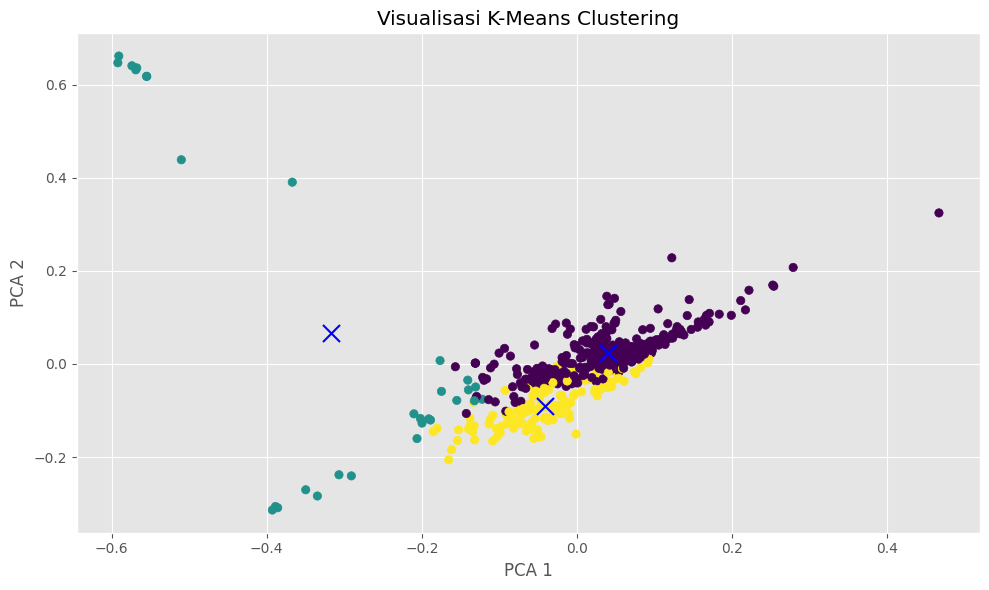

In [ ]:
# Membuat grafik hasil clustering
plt.figure(figsize=(10, 6))

plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=model_kmeans.predict(X)
)

# Menampilkan posisi centroid menggunakan tanda X
plt.scatter(
    reduced_cluster_centers[:, 0],
    reduced_cluster_centers[:, 1],
    marker="x",
    s=150,
    c="blue"
)

plt.title("Visualisasi K-Means Clustering")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.tight_layout()
plt.show()

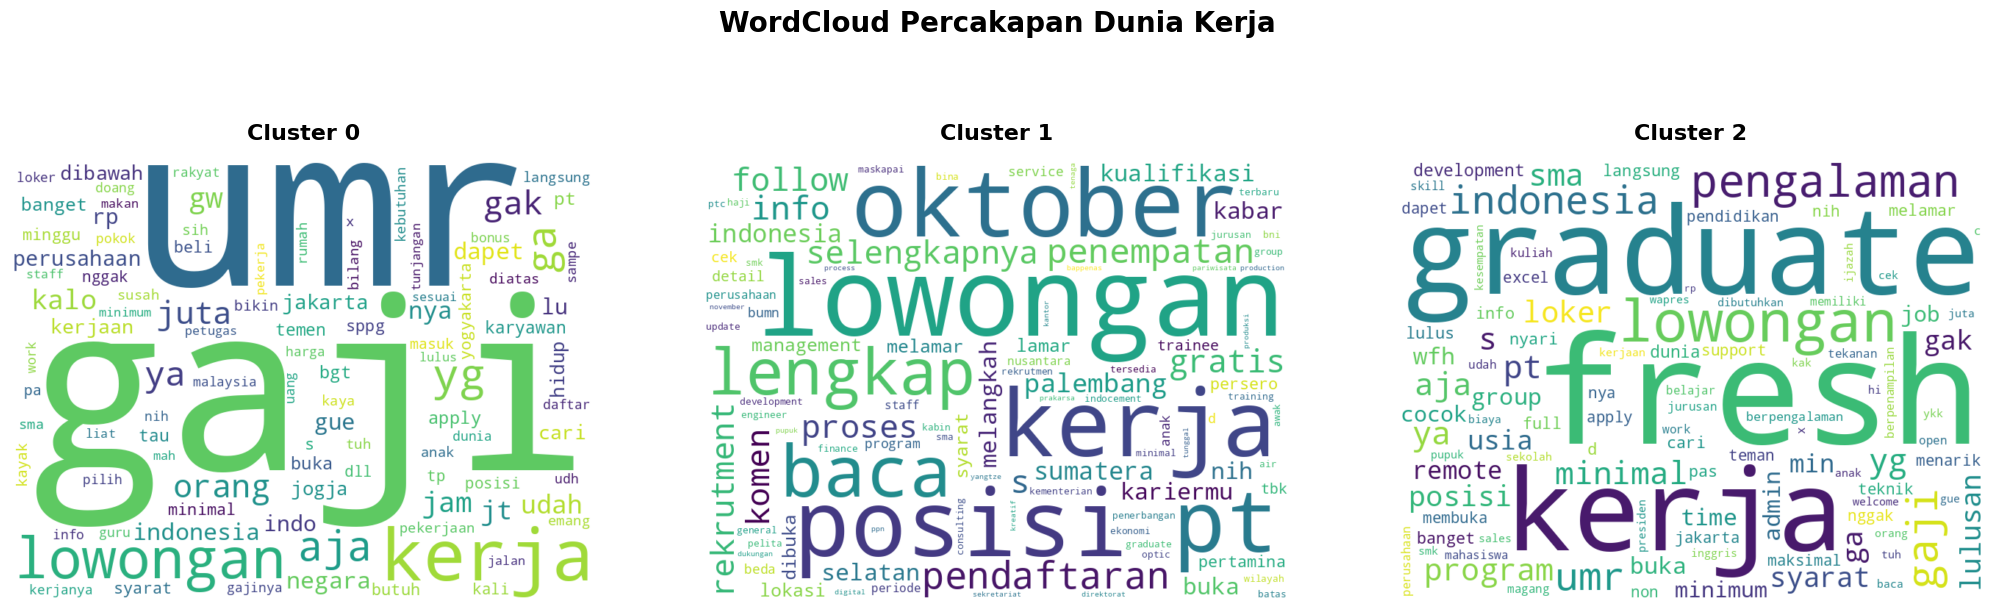

In [ ]:
# Membuat folder untuk menyimpan gambar
folder_output = "/content/wordcloud_cluster"
os.makedirs(folder_output, exist_ok=True)

# Membuat kanvas dengan 3 kolom dan jarak antargrafik
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(21, 7)
)

# Memproses setiap cluster
for i, ax in enumerate(axes):

    # Mengambil teks dari cluster terkait
    teks_cluster = df_cluster.loc[
        df_cluster["cluster"] == i, "clean_text"
    ].dropna().astype(str)

    # Menggabungkan teks menjadi satu string
    semua_teks = " ".join(teks_cluster)

    # Jika teks kosong, tampilkan keterangan
    if not semua_teks.strip():
        ax.text(
            0.5, 0.5, "Tidak ada data",
            ha="center", va="center"
        )
        ax.set_title(f"Cluster {i}")
        ax.axis("off")
        continue

    # Membuat WordCloud
    wordcloud = WordCloud(
        width=800,
        height=600,
        background_color="white",
        max_words=100,
        collocations=False,
        margin=8
    ).generate(semua_teks)

    # Menampilkan WordCloud pada kolom masing-masing
    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(
        f"Cluster {i}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.axis("off")

    # Menyimpan setiap WordCloud secara terpisah
    wordcloud.to_file(
        f"{folder_output}/wordcloud_cluster_{i}.png"
    )

# Mengatur jarak antarkolom dan margin kanvas
fig.suptitle(
    "WordCloud Percakapan Dunia Kerja",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

plt.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.82,
    bottom=0.08,
    wspace=0.18
)

plt.show()
plt.close(fig)

In [ ]:
# Membuat ringkasan jumlah data dan kata dominan setiap cluster
ringkasan_cluster = []

# Menentukan tema berdasarkan contoh postingan setiap cluster
tema_cluster = {
    0: "Diskusi Gaji, UMR, dan Tantangan Mencari Kerja",
    1: "Informasi Lowongan Kerja dan Rekrutmen",
    2: "Tantangan Fresh Graduate dan Persyaratan Pengalaman"
}

for i in range(3):
    # Menghitung jumlah postingan dalam cluster
    jumlah = int((df_cluster["cluster"] == i).sum())

    # Mengambil 5 kata dengan bobot tertinggi
    kata_dominan = [
        terms[ind]
        for ind in order_centroids[i, :5]
    ]

    # Menyimpan ringkasan setiap cluster
    ringkasan_cluster.append({
        "cluster": i,
        "jumlah_postingan": jumlah,
        "kata_dominan": ", ".join(kata_dominan),
        "tema": tema_cluster[i]
    })

# Mengubah ringkasan menjadi DataFrame
ringkasan_cluster = pd.DataFrame(ringkasan_cluster)

# Menampilkan tabel ringkasan clustering
display(ringkasan_cluster)

,cluster,jumlah_postingan,kata_dominan,tema
0,0,365,"gaji, umr, kerja, gaji umr, lowongan","Diskusi Gaji, UMR, dan Tantangan Mencari Kerja"
1,1,31,"oktober, posisi, pt, lowongan, baca",Informasi Lowongan Kerja dan Rekrutmen
2,2,120,"fresh graduate, fresh, graduate, pengalaman, k...",Tantangan Fresh Graduate dan Persyaratan Penga...


,jumlah_postingan,total_kata,rata_rata_kata,terpendek,terpanjang,tema
cluster,,,,,,
0,365,7354,20.1,2,49,"Diskusi Gaji, UMR, dan Tantangan Mencari Kerja"
1,31,608,19.6,9,29,Informasi Lowongan Kerja dan Rekrutmen
2,120,2763,23.0,4,40,Tantangan Fresh Graduate dan Persyaratan Penga...


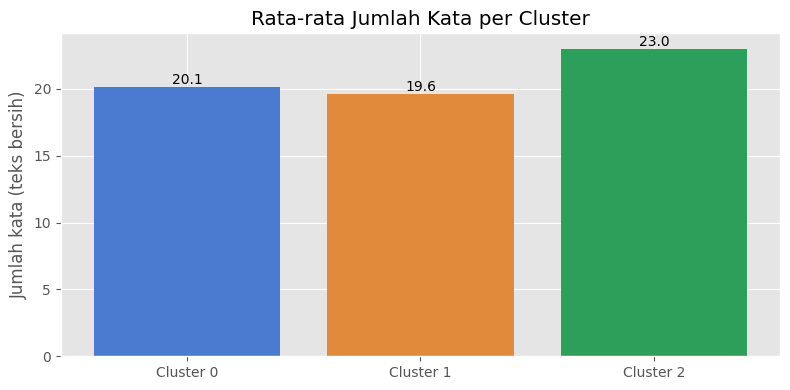

In [ ]:
# Menghitung jumlah kata pada teks bersih setiap postingan
df_cluster["jumlah_kata"] = df_cluster["clean_text"].str.split().str.len()

# Ringkasan word count per cluster
wc_cluster = df_cluster.groupby("cluster")["jumlah_kata"].agg(
    jumlah_postingan="count",
    total_kata="sum",
    rata_rata_kata="mean",
    terpendek="min",
    terpanjang="max"
).round(1)

# Menambahkan tema cluster dari tabel ringkasan sebelumnya
wc_cluster["tema"] = wc_cluster.index.map(tema_cluster)
display(wc_cluster)

# Grafik rata-rata jumlah kata per cluster
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    [f"Cluster {i}" for i in wc_cluster.index],
    wc_cluster["rata_rata_kata"],
    color=["#4a7bd0", "#e08a3c", "#2e9e5b"]
)
for b, v in zip(bars, wc_cluster["rata_rata_kata"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{v:.1f}",
            ha="center", va="bottom")
ax.set_title("Rata-rata Jumlah Kata per Cluster")
ax.set_ylabel("Jumlah kata (teks bersih)")
plt.tight_layout()
plt.show()

In [ ]:
for i in sorted(df_cluster["cluster"].unique()):
    kata = " ".join(
        df_cluster.loc[df_cluster["cluster"] == i, "clean_text"]
    ).split()

    print(f"\nCLUSTER {i} - {tema_cluster[i]}")
    print(f"Total kata: {len(kata):,} | Kata unik: {len(set(kata)):,}")

    top = pd.DataFrame(Counter(kata).most_common(10),
                       columns=["Kata", "Frekuensi"])
    display(top)


CLUSTER 0 - Diskusi Gaji, UMR, dan Tantangan Mencari Kerja
Total kata: 7,354 | Kata unik: 2,784


,Kata,Frekuensi
0,gaji,343
1,umr,312
2,kerja,282
3,lowongan,164
4,yg,90
5,aja,77
6,ga,74
7,ya,53
8,gak,48
9,orang,46



CLUSTER 1 - Informasi Lowongan Kerja dan Rekrutmen
Total kata: 608 | Kata unik: 189


,Kata,Frekuensi
0,lowongan,36
1,kerja,25
2,posisi,25
3,oktober,25
4,pt,22
5,baca,14
6,lengkap,11
7,pendaftaran,10
8,penempatan,10
9,s,9



CLUSTER 2 - Tantangan Fresh Graduate dan Persyaratan Pengalaman
Total kata: 2,763 | Kata unik: 1,141


,Kata,Frekuensi
0,fresh,106
1,graduate,105
2,kerja,92
3,lowongan,46
4,pengalaman,40
5,gaji,36
6,indonesia,30
7,umr,30
8,ya,20
9,yg,20


In [ ]:
# Kata dominan yang sama di 15 kata teratas antar cluster
top15 = {i: set(terms[j] for j in order_centroids[i, :15]) for i in range(3)}
for a in range(3):
    for b in range(a + 1, 3):
        print(f"Cluster {a} & {b}: {sorted(top15[a] & top15[b])}")

# Postingan yang hampir sama dekatnya ke dua centroid
sim = np.sort(cosine_similarity(X, model_kmeans.cluster_centers_), axis=1)
ambigu = (sim[:, -1] - sim[:, -2]) < 0.05
print(f"Postingan ambigu: {ambigu.sum()} dari {len(df_cluster)} ({ambigu.mean()*100:.1f}%)")

Cluster 0 & 1: ['lowongan', 'lowongan kerja']
Cluster 0 & 2: ['kerja', 'lowongan', 'lowongan kerja']
Cluster 1 & 2: ['lowongan', 'lowongan kerja', 'pt']
Postingan ambigu: 69 dari 516 (13.4%)


In [ ]:
# Menyimpan dataset yang sudah memiliki label cluster
df_cluster.to_csv(
    "/content/kerja_clustering.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset clustering berhasil disimpan.")

Dataset clustering berhasil disimpan.


# Analisis Sentimen Postingan


In [ ]:
from google.colab import files
import pandas as pd

KOLOM_TEKS = "Cleaned_Text"

up = files.upload()
nama_file = list(up.keys())[0]
df = pd.read_csv(nama_file) if nama_file.endswith(".csv") else pd.read_excel(nama_file)

df = df.dropna(subset=[KOLOM_TEKS]).copy()
df[KOLOM_TEKS] = df[KOLOM_TEKS].astype(str)
df = df[df[KOLOM_TEKS].str.strip() != ""].reset_index(drop=True)
df.insert(0, "id", df.index + 1)
print("Jumlah postingan:", len(df))
df.head()

Saving cleaning_kerja_relevan.csv to cleaning_kerja_relevan.csv
Jumlah postingan: 516


,id,created_at,text,Cleaned_Text,like_count,retweet_count,reply_count,is_relevant
0,1,2026-10-09 23:48:00+00:00,GOOD NEWS:\n\npemerintah akan menaikkan upah m...,good news pemerintah menaikkan upah minimum rp...,37898,4717,1465,True
1,2,2026-09-15 10:07:06+00:00,"gue abis nontonin vt ini, ada yang nanya cara ...",gue abis nontonin vt nanya kerja multinational...,14440,1515,72,True
2,3,2026-10-07 09:28:22+00:00,Baca di sini: https://t.co/tDQu9nSS2p\n\nLulus...,baca lulusan smk jakarta athalla dzaky atmaja ...,157,46,14,True
3,4,2026-10-08 02:42:59+00:00,Mimpi Basah Para Pejuang loker di Indonesia\n\...,mimpi basah pejuang loker indonesia syarat pen...,2550,818,168,True
4,5,2026-09-01 15:28:14+00:00,📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi ...,lowongan kerja mayora mdp kualifikasi terbuka ...,590,46,2,True


In [ ]:
import torch
from transformers import pipeline

MODEL = "mdhugol/indonesia-bert-sentiment-classification"
PETA = {"LABEL_0": "Positif", "LABEL_1": "Netral", "LABEL_2": "Negatif",
        "positive": "Positif", "neutral": "Netral", "negative": "Negatif"}

clf = pipeline("text-classification", model=MODEL, tokenizer=MODEL,
               device=0 if torch.cuda.is_available() else -1)

hasil = clf(df[KOLOM_TEKS].tolist(), batch_size=32, truncation=True, max_length=128)
df["sentimen_sistem"] = [PETA.get(h["label"], h["label"]) for h in hasil]
df["skor"] = [round(h["score"], 4) for h in hasil]
df[["id", KOLOM_TEKS, "sentimen_sistem", "skor"]].head()

config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,id,Cleaned_Text,sentimen_sistem,skor
0,1,good news pemerintah menaikkan upah minimum rp...,Netral,0.9896
1,2,gue abis nontonin vt nanya kerja multinational...,Negatif,0.9852
2,3,baca lulusan smk jakarta athalla dzaky atmaja ...,Netral,0.9869
3,4,mimpi basah pejuang loker indonesia syarat pen...,Netral,0.9751
4,5,lowongan kerja mayora mdp kualifikasi terbuka ...,Netral,0.9850


,Jumlah,Persentase (%)
sentimen_sistem,,
Positif,45,8.72
Negatif,211,40.89
Netral,260,50.39


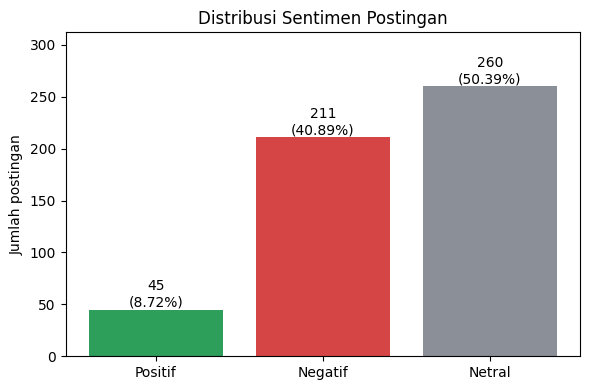

In [ ]:
import matplotlib.pyplot as plt

urutan = ["Positif", "Negatif", "Netral"]
jumlah = df["sentimen_sistem"].value_counts().reindex(urutan, fill_value=0)
ringkasan = pd.DataFrame({"Jumlah": jumlah,
                          "Persentase (%)": (jumlah / jumlah.sum() * 100).round(2)})
display(ringkasan)

warna = ["#2e9e5b", "#d64545", "#8a8f98"]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(ringkasan.index, ringkasan["Jumlah"], color=warna)
for b, p in zip(bars, ringkasan["Persentase (%)"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{int(b.get_height())}\n({p}%)",
            ha="center", va="bottom")
ax.set_title("Distribusi Sentimen Postingan")
ax.set_ylabel("Jumlah postingan")
ax.set_ylim(0, ringkasan["Jumlah"].max() * 1.2)
plt.tight_layout(); plt.show()

In [ ]:
pd.set_option("display.max_colwidth", 200)
tabel = df[["id", KOLOM_TEKS, "sentimen_sistem", "skor"]]
display(df)
df.to_csv("hasil_sentimen_lengkap.csv", index=False)
files.download("hasil_sentimen_lengkap.csv")

,id,created_at,text,Cleaned_Text,like_count,retweet_count,reply_count,is_relevant,sentimen_sistem,skor
0,1,2026-10-09 23:48:00+00:00,"GOOD NEWS:\n\npemerintah akan menaikkan upah minimum menjadi Rp 8,76 juta sedangkan untuk fresh graduate upah awal minimum sebesar Rp 10,95 juta\n\nkenaika ini bertujuan meringankan beban masyarak...",good news pemerintah menaikkan upah minimum rp juta fresh graduate upah minimum rp juta kenaika bertujuan meringankan beban masyarakat ditengah naiknya biaya hidup datuk anwar pm malaysia,37898,4717,1465,True,Netral,0.9896
1,2,2026-09-15 10:07:06+00:00,"gue abis nontonin vt ini, ada yang nanya cara kerja di ‘multinational company’ kayak dia…\n\ndan ada beberapa fakta MENYEDIHKAN yang dia kasih tau:\n- job market sekarang JAUH beda sama 2016\n- se...",gue abis nontonin vt nanya kerja multinational company kayak fakta menyedihkan kasih tau job market beda fresh graduate aja susah cari kerja,14440,1515,72,True,Negatif,0.9852
2,3,2026-10-07 09:28:22+00:00,"Baca di sini: https://t.co/tDQu9nSS2p\n\nLulusan SMK 5 Jakarta Athalla Dzaky Atmaja (18) harus menghadapi sulitnya mencari pekerjaan pertama karena banyak lowongan mensyaratkan pengalaman, meski i...",baca lulusan smk jakarta athalla dzaky atmaja menghadapi sulitnya mencari pekerjaan lowongan mensyaratkan pengalaman berkali kali mengirim lamaran job fair situs pencari kerja,157,46,14,True,Netral,0.9869
3,4,2026-10-08 02:42:59+00:00,"Mimpi Basah Para Pejuang loker di Indonesia\n\nSYARAT :\nPendidikan min: SMA/SMK/D3/S1 semua jurusan\nFresh graduate boleh melamar\nJujur, teliti, mau belajar\nTidak ada batas usia (selama masih ...",mimpi basah pejuang loker indonesia syarat pendidikan min sma smk d s jurusan fresh graduate melamar jujur teliti belajar batas usia kuat kerja syarat berpenampilan menarik gaji benefit gaji rp,2550,818,168,True,Netral,0.9751
4,5,2026-09-01 15:28:14+00:00,"📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi Umum :\n* Terbuka untuk Fresh Graduate atau memiliki pengalaman kerja maksimal 2 tahun\n* IPK minimal 3,25\n* Memiliki pengalaman organisasi dan perna...",lowongan kerja mayora mdp kualifikasi terbuka fresh graduate memiliki pengalaman kerja maksimal ipk minimal memiliki pengalaman organisasi pemimpin berbahasa inggris aktif memiliki,590,46,2,True,Netral,0.9850
...,...,...,...,...,...,...,...,...,...,...
511,512,2021-10-24 04:53:49+00:00,kcg! dicari 1 org yg siap ngurusin 8 kucing di surabaya kalau bisa berpengalaman ( tau persia dan ragdoll) lebih dari 3-5 thn daerah ciputra gaji umr sby makan minum anda saya tanggung -titipan *...,kcg dicari org yg ngurusin kucing surabaya berpengalaman tau persia ragdoll thn daerah ciputra gaji umr sby makan minum tanggung titipan ku ketuk dm kakak,5,6,1,True,Netral,0.9757
512,513,2026-10-09 02:36:53+00:00,"Lowongan Kerja Hisana Palembang Oktober 2026\n\nPenempatan: Palembang, Sumatera Selatan\nBaca Selengkapnya👇\nhttps://t.co/xaGJOpDqWb\n\nLike, Komen &amp; Follow\n@Infolokerplg \n@Infolokerplg \n\n...",lowongan kerja hisana palembang oktober penempatan palembang sumatera selatan baca selengkapnya like komen follow proses rekrutment gratis,1,0,0,True,Netral,0.9950
513,514,2026-10-08 09:13:54+00:00,"""gais aku terpaksa korupsi duit pajak kalian soalnya aku udh sekian tahun nganggur dan udah didesak sana sini""\n\naku dan pajak2ku yg dibayarkan dr gaji umr itu : 👁️👄👁️",gais terpaksa korupsi duit pajak udh sekian nganggur udah didesak pajak ku yg dibayarkan dr gaji umr,2,0,0,True,Negatif,0.9930
514,515,2026-10-09 13:21:00+00:00,"Ini pendapat AWAM makanya ABSURB, karena sejak KAPAN dan DIMANA, mereka yang Ingin Menjadi PEMIMPIN atau PENGUSAHA sama seperti MELAMAR Pekerjaan, seperti Orang yang Ingin BEKERJA pada sebuah peru...",pendapat awam absurb dimana pemimpin pengusaha melamar pekerjaan orang perusahaan ijazah bukti administrasu orang sekolah,1,1,0,True,Negatif,0.8568


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
sampel = df.sample(n=20, random_state=42)
untuk_label = sampel[["id", KOLOM_TEKS]].copy()
untuk_label["label_manual"] = ""
untuk_label.to_excel("evaluasi_sentimen_manual.xlsx", index=False)
files.download("evaluasi_sentimen_manual.xlsx")
print("Isi kolom label_manual bersama kelompok (Positif/Negatif/Netral), simpan, lalu upload di langkah selanjutnya .")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Isi kolom label_manual bersama kelompok (Positif/Negatif/Netral), simpan, lalu upload di langkah .


In [ ]:
up2 = files.upload()
manual = pd.read_excel(list(up2.keys())[0])

def norm(x):
    x = str(x).strip().lower()
    return {"positif": "Positif", "positive": "Positif",
            "negatif": "Negatif", "negative": "Negatif",
            "netral": "Netral", "neutral": "Netral"}.get(x, x)

manual["label_manual"] = manual["label_manual"].apply(norm)
cek = manual[["id", "label_manual"]].merge(
    df[["id", KOLOM_TEKS, "sentimen_sistem", "skor"]], on="id", how="left")
cek["sesuai"] = cek["label_manual"] == cek["sentimen_sistem"]

n_sesuai = int(cek["sesuai"].sum())
print(f"Sesuai      : {n_sesuai} dari {len(cek)} ({n_sesuai/len(cek)*100:.1f}%)")
print(f"Tidak sesuai: {len(cek)-n_sesuai} dari {len(cek)} ({(len(cek)-n_sesuai)/len(cek)*100:.1f}%)")
display(cek)

nama_file = "hasil_comparison_sentimen.xlsx"

cek.to_excel(nama_file, index=False)

files.download(nama_file)

Saving evaluasi_sentimen_manual.xlsx to evaluasi_sentimen_manual.xlsx
Sesuai      : 16 dari 20 (80.0%)
Tidak sesuai: 4 dari 20 (20.0%)


,id,label_manual,Cleaned_Text,sentimen_sistem,skor,sesuai
0,305,Netral,konsisten profit lping pencapaian remeh profit gt profit segini konsisten disiplin plan compound udah ngalahin gaji umr pengen belajar lp meteora cek pin post disana uda,Netral,0.9228,True
1,501,Netral,lowongan kerja presiden ri persyaratan pria wanita waria pendidikan min paud gak pintar rajin jujur dll jago ngibul bahasa inggris gaji umr dki kalo temen memenuhi kriteria silahkan hubungi,Netral,0.9495,True
2,442,Netral,lamar kerja perusahaan yg wa teller proses adm tinggal masuk start up gaji umr penempatan deket rumah jdi teller cs bank bumn proses intrv kontrak doang penempatan blm tau cro tahap intrv,Netral,0.7886,True
3,154,Positif,gaji umr aroma badan usahakan direktur,Netral,0.9945,False
4,503,Negatif,tau ngga rakyat yg gaji umr ngira gaji rakyat sebulan jt wkwkwk,Negatif,0.9067,True
5,132,Netral,guys bantu sebar lowongan kerja uniqlo nih penempatan kelapa gading pluit bekasi gaji umr cewe hijaban minat dm aja yaaa,Netral,0.9929,True
6,205,Netral,mimpi basah fresh graduate,Negatif,0.9749,False
7,512,Netral,kcg dicari org yg ngurusin kucing surabaya berpengalaman tau persia ragdoll thn daerah ciputra gaji umr sby makan minum tanggung titipan ku ketuk dm kakak,Netral,0.9757,True
8,326,Negatif,bayaran wnt pabrik gede drpd bayaran anak fresh graduate skillnya bumi langit china mainland pake bor aja gabisa,Negatif,0.5510,True
9,248,Negatif,tbh gue nangis aja si temen gue bgt lulusan sma smk susah cari kerja bgt gaji umr sarjana but they have no money kuliah temen temen gue rezeki kuliah mampus organisasi magang,Negatif,0.9961,True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Regresi Linear

In [ ]:
# Membaca dataset hasil tahapan sebelumnya (sesuaikan nama file)
df = pd.read_csv('hasil_sentimen_lengkap.csv')

# 1. Hitung jumlah kata dan jumlah hashtag dari TEKS ASLI ('text') untuk analisis Heatmap
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))
df['hashtag_count'] = df['text'].astype(str).apply(lambda x: len(re.findall(r'#\w+', x)))

# 2. Pastikan kolom target 'like_count' & fitur 'retweet_count', 'reply_count' bernilai numerik valid (JANGAN ganti NaN menjadi 0)
for col in ['like_count', 'retweet_count', 'reply_count']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['like_count_num'] = df['like_count']
df_reg = df.dropna(subset=['like_count_num', 'retweet_count', 'reply_count']).copy()

print(f"Total baris awal                : {len(df)} baris")
print(f"Baris dengan data tidak valid   : {len(df) - len(df_reg)} baris (Dihapus)")
print(f"Total data valid untuk regresi  : {len(df_reg)} baris\n")

# Menampilkan 5 sampel data fitur dan target
display(df_reg[['id', 'text', 'word_count', 'hashtag_count', 'retweet_count', 'reply_count', 'like_count_num']].head())

Total baris awal                : 516 baris
Baris dengan data tidak valid   : 0 baris (Dihapus)
Total data valid untuk regresi  : 516 baris



,id,text,word_count,hashtag_count,retweet_count,reply_count,like_count_num
0,1,GOOD NEWS:\n\npemerintah akan menaikkan upah m...,38,0,4717,1465,37898
1,2,"gue abis nontonin vt ini, ada yang nanya cara ...",49,0,1515,72,14440
2,3,Baca di sini: https://t.co/tDQu9nSS2p\n\nLulus...,37,0,46,14,157
3,4,Mimpi Basah Para Pejuang loker di Indonesia\n\...,42,0,818,168,2550
4,5,📢 Lowongan Kerja Mayora (MDP)\n\n📌Kualifikasi ...,42,0,46,2,590


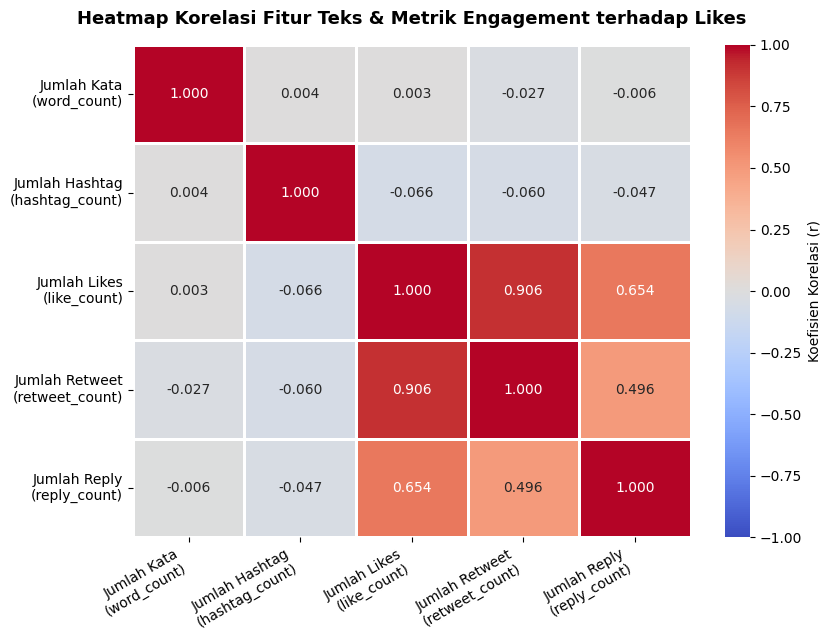

In [ ]:
# Pastikan kelima kolom bertipe numerik terlebih dahulu
for col in ['like_count', 'retweet_count', 'reply_count']:
    df_reg[col] = pd.to_numeric(df_reg[col], errors='coerce')

# Menghitung matriks korelasi untuk seluruh fitur teks dan metrik engagement
kolom_korelasi = ['word_count', 'hashtag_count', 'like_count', 'retweet_count', 'reply_count']
nama_label = [
    'Jumlah Kata\n(word_count)',
    'Jumlah Hashtag\n(hashtag_count)',
    'Jumlah Likes\n(like_count)',
    'Jumlah Retweet\n(retweet_count)',
    'Jumlah Reply\n(reply_count)'
]

corr_matrix = df_reg[kolom_korelasi].corr()

# Membuat visualisasi Heatmap
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",          # Bisa diubah ke ".4f" jika ingin 4 angka di belakang koma
    cmap="coolwarm",
    vmin=-1, vmax=1,
    xticklabels=nama_label,
    yticklabels=nama_label,
    linewidths=1,
    cbar_kws={'label': 'Koefisien Korelasi (r)'}
)
plt.title("Heatmap Korelasi Fitur Teks & Metrik Engagement terhadap Likes", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Menentukan fitur masukan (X) dan target (y)
X = df_reg[['reply_count', 'retweet_count']]
y = df_reg['like_count']

# 3 & 4. Membagi data menjadi 80% data latih dan 20% data uji dengan random_state tetap
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Melatih model Regresi Linear HANYA menggunakan data latih
model_reg = LinearRegression()
model_reg.fit(X_train, y_train)

print("=== PEMBAGIAN DATA & PARAMETER MODEL ===")
print(f"Jumlah Data Latih (80%) : {len(X_train)} baris")
print(f"Jumlah Data Uji (20%)   : {len(X_test)} baris")
print("-" * 42)
print(f"Intercept (Konstanta)   : {model_reg.intercept_:,.4f}")
print(f"Koefisien reply_count   : {model_reg.coef_[0]:,.4f}")
print(f"Koefisien retweet_count : {model_reg.coef_[1]:,.4f}")
print("\nPersamaan Regresi:")
print(f"Likes = {model_reg.intercept_:.2f} + ({model_reg.coef_[0]:.2f} * reply_count) + ({model_reg.coef_[1]:.2f} * retweet_count)")

=== PEMBAGIAN DATA & PARAMETER MODEL ===
Jumlah Data Latih (80%) : 412 baris
Jumlah Data Uji (20%)   : 104 baris
------------------------------------------
Intercept (Konstanta)   : 176.1814
Koefisien reply_count   : 15.8110
Koefisien retweet_count : 2.7806

Persamaan Regresi:
Likes = 176.18 + (15.81 * reply_count) + (2.78 * retweet_count)


=== HASIL EVALUASI MODEL PADA DATA UJI ===
Fitur Masukan (X)           : reply_count & retweet_count
Target Prediksi (y)         : like_count
---------------------------------------------
Mean Absolute Error (MAE)   : 912.40
R² Score (Koef. Determinasi): 0.8788 (87.88%)



,reply_count,retweet_count,Likes_Aktual,Likes_Prediksi,Selisih_Error
304,9,0,41,318.48,277.48
500,9,9,23,343.51,320.51
441,1,0,0,191.99,191.99
153,1,2,5,197.55,192.55
502,0,0,2,176.18,174.18


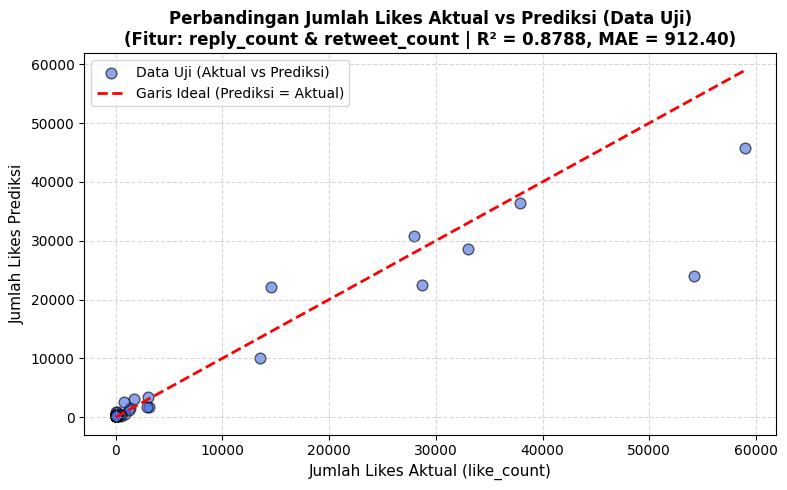

In [ ]:
# 6. Prediksi dan evaluasi menggunakan MAE dan R² pada DATA UJI
y_pred = model_reg.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL PADA DATA UJI ===")
print("Fitur Masukan (X)           : reply_count & retweet_count")
print("Target Prediksi (y)         : like_count")
print("-" * 45)
print(f"Mean Absolute Error (MAE)   : {mae:,.2f}")
print(f"R² Score (Koef. Determinasi): {r2:.4f} ({r2*100:.2f}%)\n")

# Menampilkan 5 sampel perbandingan Likes Aktual vs Prediksi pada Data Uji
df_hasil_uji = X_test.copy()
df_hasil_uji['Likes_Aktual'] = y_test.values
df_hasil_uji['Likes_Prediksi'] = y_pred.round(2)
df_hasil_uji['Selisih_Error'] = (df_hasil_uji['Likes_Aktual'] - df_hasil_uji['Likes_Prediksi']).abs().round(2)
display(df_hasil_uji.head())

# 7. Menampilkan grafik jumlah likes aktual dibandingkan hasil prediksi
plt.figure(figsize=(8, 5))
plt.scatter(
    y_test, y_pred,
    color='royalblue', alpha=0.6, edgecolors='k', s=60,
    label='Data Uji (Aktual vs Prediksi)'
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--', lw=2,
    label='Garis Ideal (Prediksi = Aktual)'
)

plt.title(
    f"Perbandingan Jumlah Likes Aktual vs Prediksi (Data Uji)\n(Fitur: reply_count & retweet_count | R² = {r2:.4f}, MAE = {mae:,.2f})",
    fontsize=12, fontweight='bold'
)
plt.xlabel("Jumlah Likes Aktual (like_count)", fontsize=11)
plt.ylabel("Jumlah Likes Prediksi", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# @title 🧮 Formulir Estimasi Jumlah Likes Postingan { run: "auto" }
jumlah_reply = 235 # @param {type:"slider", min:0, max:1500, step:5}
jumlah_retweet = 100 # @param {type:"slider", min:0, max:5000, step:10}

# Membentuk DataFrame input sesuai urutan nama fitur saat pelatihan di Cell 3
input_user = pd.DataFrame({
    'reply_count': [jumlah_reply],
    'retweet_count': [jumlah_retweet]
})

# Menghitung estimasi likes
estimasi_likes = model_reg.predict(input_user)[0]

print("=== HASIL ESTIMASI MODEL REGRESI LINEAR ===")
print(f"Fitur Masukan 1 (Jumlah Reply)   : {jumlah_reply} reply")
print(f"Fitur Masukan 2 (Jumlah Retweet) : {jumlah_retweet} retweet")
print("-" * 45)
print(f"📌 Estimasi Jumlah Likes         : {estimasi_likes:,.2f} likes")

if estimasi_likes < 0:
    print("\n⚠️ CATATAN KETERBATASAN MODEL:")
    print("Hasil estimasi bernilai NEGATIF. Secara nyata, jumlah likes tidak mungkin bernilai negatif")
    print("dan menunjukkan keterbatasan model regresi linear sederhana.")

NameError: name 'pd' is not defined

### Interpretasi Hasil Regresi Linear

* **Makna Nilai MAE (`912.40`):**
  Nilai *Mean Absolute Error* (MAE) sebesar **912.40** menunjukkan bahwa rata-rata selisih absolut antara prediksi model dan jumlah *likes* aktual pada data uji adalah sekitar **912 likes** (jauh lebih akurat dibandingkan model jumlah kata dan hashtag yang memiliki MAE **3,728.04**). Selisih ini dipengaruhi oleh adanya *outlier* postingan viral yang mencapai hingga 37.898 *likes*.

* **Makna Nilai $R^2$ (`0.8788`) & Makna Jika $R^2$ Negatif:**
  * **Pada fitur `reply_count` dan `retweet_count`:** Nilai $R^2$ sebesar **0.8788** menunjukkan bahwa **87.88%** variasi jumlah *likes* pada data uji dapat dijelaskan oleh jumlah *reply* dan *retweet*.
  * **Jika nilai $R^2$ negatif (seperti pada fitur `word_count` dan `hashtag_count` yang menghasilkan $R^2 = -0.0182$):** Nilai $R^2$ negatif berarti fitur masukan tidak memiliki hubungan linear dengan target, sehingga prediksi garis regresi pada data uji justru menghasilkan error yang lebih besar dibandingkan jika hanya menebak menggunakan nilai rata-rata (*mean*) target.

* **Keterbatasan Penggunaan Dua Fitur untuk Memperkirakan Likes:**
  Dua fitur saja tidak cukup mewakili dinamika interaksi media sosial secara utuh. Fitur `reply_count` dan `retweet_count` baru dapat diketahui setelah postingan diunggah, sedangkan fitur `word_count` dan `hashtag_count` tidak berkorelasi dengan interaksi. Pada kenyataannya, jumlah *likes* juga sangat dipengaruhi oleh faktor lain seperti **usia postingan**, **jangkauan akun (jumlah *followers*)**, dan **isi pesan**.

* **Penjelasan Estimasi Negatif pada Regresi Linear:**
  Regresi linear dapat menghasilkan estimasi negatif apabila koefisien fiturnya bernilai negatif dan diberi nilai input yang besar. Hasil estimasi negatif tersebut **tidak bermakna sebagai jumlah *likes* nyata** (karena jumlah *likes* paling rendah adalah 0) dan menunjukkan keterbatasan model regresi linear sederhana yang mengasumsikan garis lurus tanpa batas bawah.